# Part 3: Visualizations
**Project:** Crime in India: Exploratory Data Analysis & Visualization
**Input:** the cleaned files from Part 1 (`data/processed/`)

| # | Chart | Type |
|---|---|---|
| 1 | National trend of IPC crimes | line |
| 2 | Top 10 states by total crime | horizontal bar |
| 3 | State x Year heatmap | heatmap |
| 4 | Crime-type composition by year | 100% stacked bar |
| 5 | Growth of serious crimes (index) | interactive lines |
| 6 | Crimes against women | stacked bar |
| 7 | District spread inside top-10 states | box plot |
| 8 | State to district contribution | interactive treemap |
| 9 | Trend in the top 5 states | line |
| 10 | India map of crime by state | interactive map |

Static charts are saved as PNG and interactive charts as HTML in the `visuals/` folder. Each chart is followed by an **Insight** line that is calculated from your data.

**Run `01_data_cleaning.ipynb` first.** Chart 10 needs an internet connection the first time (it downloads state boundaries).

## 0. Setup and load the cleaned data

In [17]:
import json
import re
import warnings
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import plotly.express as px
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
VISUALS_DIR = ROOT / "visuals"
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

district_file = PROCESSED_DIR / "crime_ipc_district_clean.csv"
state_file = PROCESSED_DIR / "crime_ipc_state_year.csv"
for f in (district_file, state_file):
    if not f.exists():
        raise FileNotFoundError(f"{f.name} not found. Run 01_data_cleaning.ipynb first.")

df = pd.read_csv(district_file)          # state + district + year
state_year = pd.read_csv(state_file)     # state + year

TOTAL_COL = "total_ipc_crimes"
needed = ["state", "district", "year", TOTAL_COL]
if any(c not in df.columns for c in needed):
    raise ValueError(f"Expected columns {needed}. Found: {list(df.columns)}")

CRIME_COLS = [c for c in df.columns if c not in ["state", "district", "year"]]
MAIN_CANDIDATES = [
    "murder", "attempt_to_murder", "rape", "kidnapping_abduction", "dacoity",
    "robbery", "burglary", "theft", "riots", "cheating", "criminal_breach_of_trust",
    "arson", "hurt_grevious_hurt", "dowry_deaths", "causing_death_by_negligence",
]
MAIN_CRIMES = [c for c in MAIN_CANDIDATES if c in df.columns]
if len(MAIN_CRIMES) < 3:
    raise ValueError(f"Too few main crime columns found. Columns: {CRIME_COLS}")

# Helpers
thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")
pretty = lambda name: name.replace("_", " ").title()

def save_png(fig, name):
    fig.savefig(VISUALS_DIR / name, dpi=150, bbox_inches="tight")

def save_html(fig, name):
    fig.write_html(VISUALS_DIR / name, include_plotlyjs="cdn")

# Tables used by several charts
national = state_year.groupby("year")[TOTAL_COL].sum()
state_totals = state_year.groupby("state")[TOTAL_COL].sum().sort_values(ascending=False)
types_by_year = state_year.groupby("year")[MAIN_CRIMES].sum()
top10 = state_totals.head(10).index.tolist()
top15 = state_totals.head(15).index.tolist()
first_year, last_year = int(national.index.min()), int(national.index.max())

print(f"Years {first_year}-{last_year} | {state_year['state'].nunique()} states/UTs | {df['district'].nunique()} districts")
print("Main crime columns:", MAIN_CRIMES)

Years 2001-2013 | 35 states/UTs | 825 districts
Main crime columns: ['murder', 'attempt_to_murder', 'rape', 'kidnapping_abduction', 'dacoity', 'robbery', 'burglary', 'theft', 'riots', 'cheating', 'criminal_breach_of_trust', 'arson', 'hurt_grevious_hurt', 'dowry_deaths', 'causing_death_by_negligence']


## Chart 1: National trend of registered IPC crimes
**Question:** is total registered crime going up or down over the years?

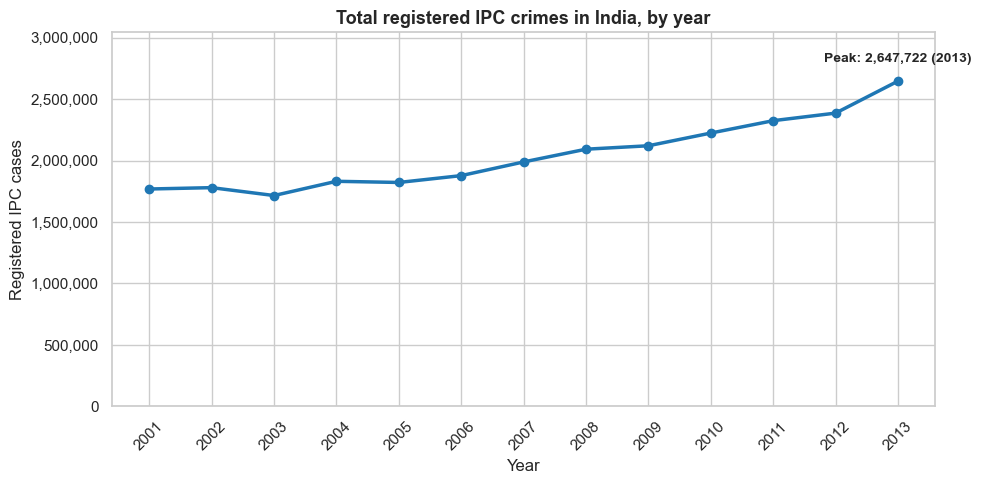

Insight: registered IPC crime changed by +49.6% between 2001 and 2013, and peaked in 2013.


In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(national.index, national.values, marker="o", linewidth=2.5, color="#1f77b4")

peak_year = int(national.idxmax())
ax.annotate(f"Peak: {national.max():,.0f} ({peak_year})",
            xy=(peak_year, national.max()), xytext=(0, 14), textcoords="offset points",
            ha="center", fontsize=10, fontweight="bold")

ax.set_title("Total registered IPC crimes in India, by year", fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Registered IPC cases")
ax.set_xticks(national.index)
ax.tick_params(axis="x", rotation=45)
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0, national.max() * 1.15)
plt.tight_layout()
save_png(fig, "03_01_national_trend.png")
plt.show()

change = (national.loc[last_year] / national.loc[first_year] - 1) * 100
print(f"Insight: registered IPC crime changed by {change:+.1f}% between {first_year} and {last_year}, "
      f"and peaked in {peak_year}.")

## Chart 2: Top 10 states/UTs by total crime
**Question:** where is the most crime registered? (Counts, not rates: big states have more people.)

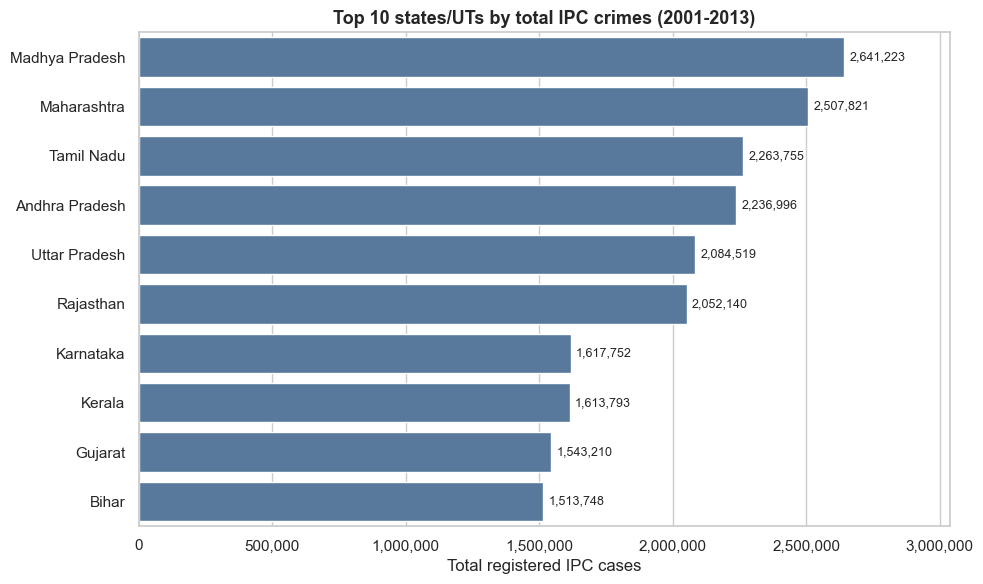

Insight: Madhya Pradesh has the most registered crime. The top 3 states together account for 27.9% of all cases.


In [19]:
top10_values = state_totals.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top10_values.values, y=top10_values.index, color="#4c78a8", ax=ax)
ax.bar_label(ax.containers[0], labels=[f"{v:,.0f}" for v in top10_values.values], padding=4, fontsize=9)

ax.set_title(f"Top 10 states/UTs by total IPC crimes ({first_year}-{last_year})", fontsize=13, fontweight="bold")
ax.set_xlabel("Total registered IPC cases")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, top10_values.max() * 1.15)
plt.tight_layout()
save_png(fig, "03_02_top10_states.png")
plt.show()

share = state_totals.head(3).sum() / state_totals.sum() * 100
print(f"Insight: {top10_values.index[0]} has the most registered crime. The top 3 states together account for {share:.1f}% of all cases.")

## Chart 3: Heatmap of states across years
**Question:** which states stay high year after year, and where did things change suddenly? Values are in thousands of cases, for the 15 states with the most crime.

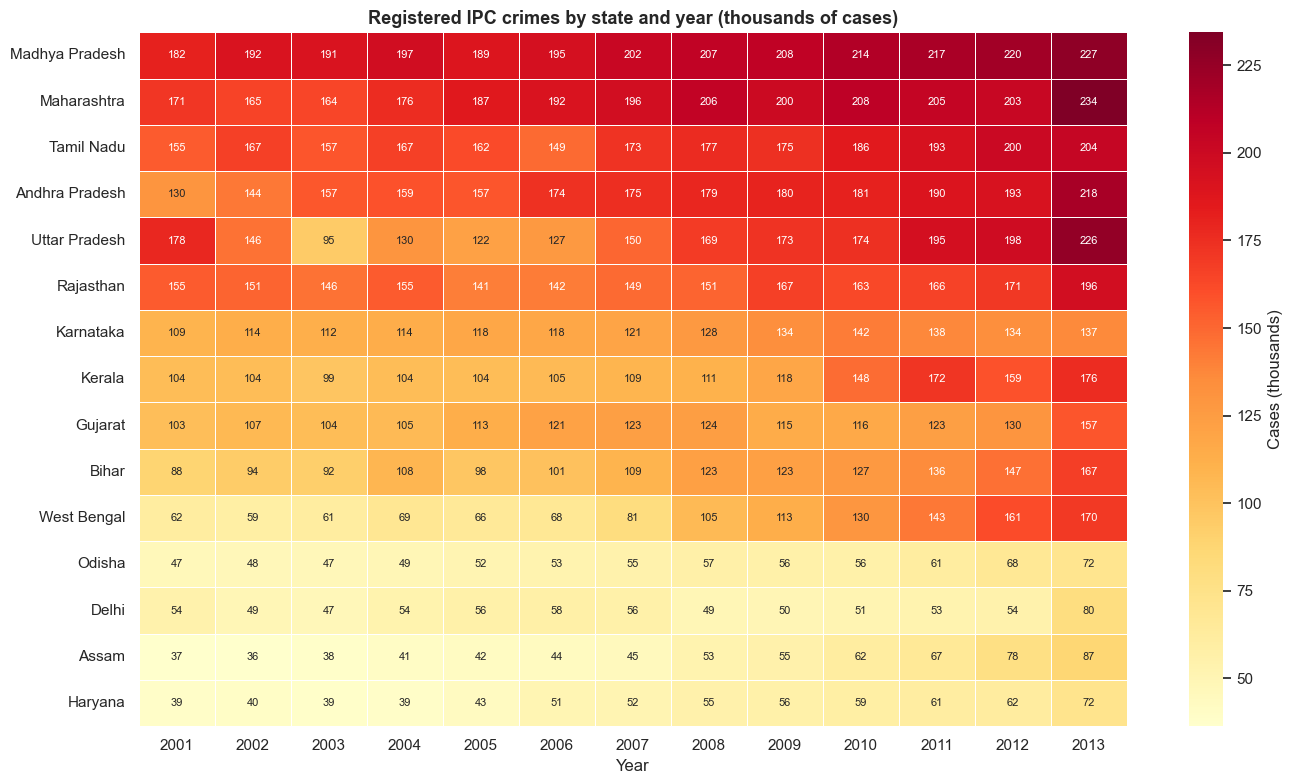

Insight: the single highest cell is Maharashtra in 2013 (234 thousand cases).


In [20]:
pivot = (
    state_year[state_year["state"].isin(top15)]
    .pivot_table(index="state", columns="year", values=TOTAL_COL, aggfunc="sum")
    .loc[top15] / 1000
)

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 8},
            linewidths=0.5, cbar_kws={"label": "Cases (thousands)"}, ax=ax)
ax.set_title("Registered IPC crimes by state and year (thousands of cases)", fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("")
plt.tight_layout()
save_png(fig, "03_03_state_year_heatmap.png")
plt.show()

hot_state, hot_year = pivot.stack().idxmax()
print(f"Insight: the single highest cell is {hot_state} in {hot_year} ({pivot.stack().max():,.0f} thousand cases).")

## Chart 4: Which crime types make up the total?
**Question:** how does the mix of crime types change over the years? Each bar is 100%. The 7 largest crime types are shown, and the rest are grouped.

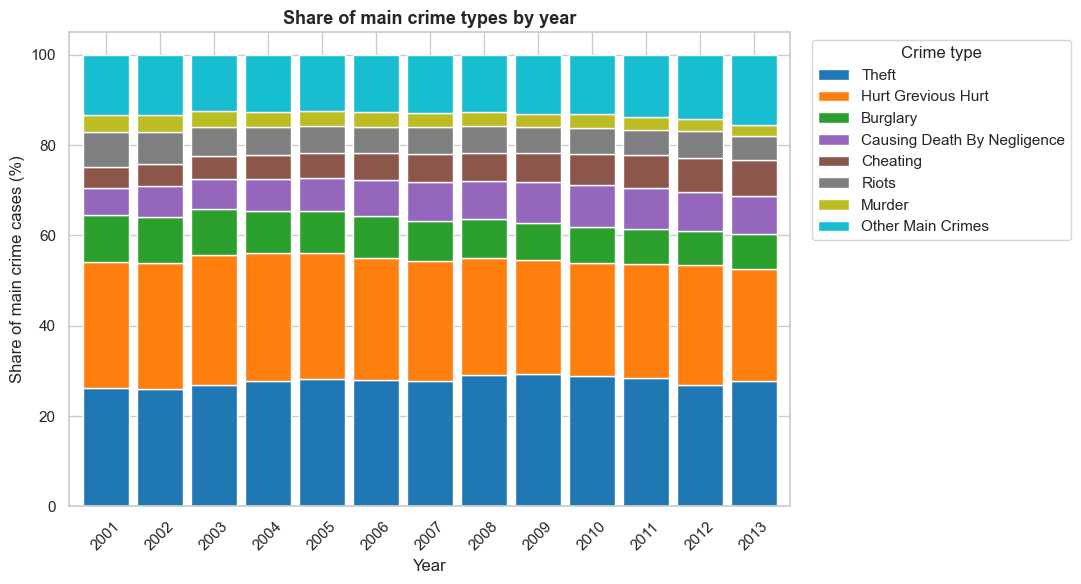

Insight: the biggest gain in share is Cheating (+3.4 percentage points); the biggest drop is Hurt Grevious Hurt (-3.1 points) between 2001 and 2013.


In [21]:
top_types = types_by_year.sum().sort_values(ascending=False).head(7).index.tolist()
comp = types_by_year[top_types].copy()
rest = types_by_year.drop(columns=top_types).sum(axis=1)
if rest.sum() > 0:
    comp["other_main_crimes"] = rest
comp_pct = comp.div(comp.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 6))
comp_pct.plot(kind="bar", stacked=True, ax=ax, colormap="tab10", width=0.85)
ax.set_title("Share of main crime types by year", fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Share of main crime cases (%)")
ax.tick_params(axis="x", rotation=45)
ax.legend([pretty(c) for c in comp_pct.columns], bbox_to_anchor=(1.02, 1), loc="upper left", title="Crime type")
plt.tight_layout()
save_png(fig, "03_04_crime_composition.png")
plt.show()

shift = (comp_pct.loc[last_year] - comp_pct.loc[first_year]).sort_values()
print(f"Insight: the biggest gain in share is {pretty(shift.index[-1])} ({shift.iloc[-1]:+.1f} percentage points); "
      f"the biggest drop is {pretty(shift.index[0])} ({shift.iloc[0]:+.1f} points) between {first_year} and {last_year}.")

## Chart 5: Growth of serious crimes (interactive)
**Question:** which serious crimes grew fastest? Every line starts at 100 in the first year, so crimes of very different sizes can be compared. Hover over a line to see values.

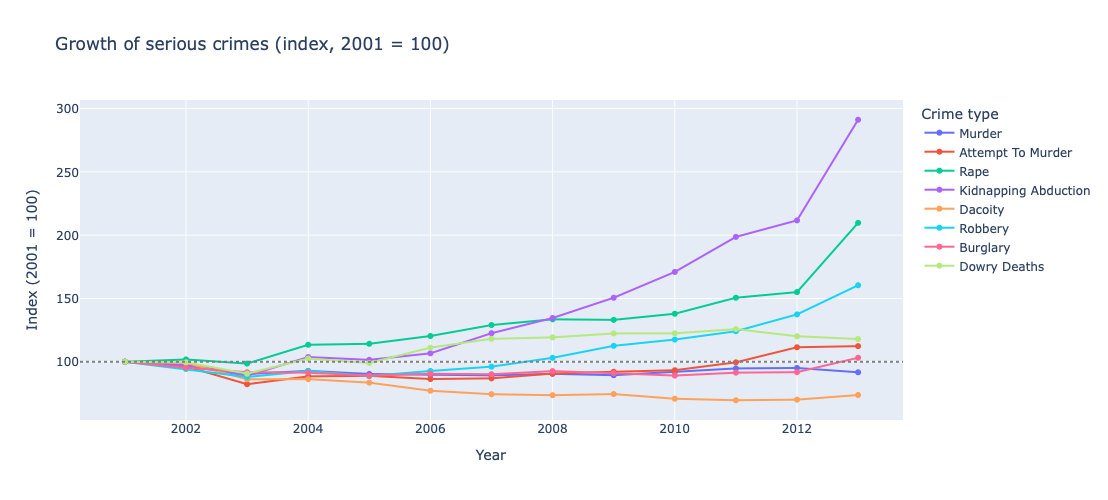

Insight: by 2013, Kidnapping Abduction is at 291 (vs 100 in 2001) and Dacoity is at 74.


In [22]:
serious_candidates = ["murder", "attempt_to_murder", "rape", "kidnapping_abduction",
                      "dacoity", "robbery", "burglary", "dowry_deaths"]
serious = [c for c in serious_candidates if c in types_by_year.columns and types_by_year[c].iloc[0] > 0]

index_df = types_by_year[serious].div(types_by_year[serious].iloc[0]) * 100
index_df.columns = [pretty(c) for c in index_df.columns]

fig = px.line(index_df, markers=True,
              title=f"Growth of serious crimes (index, {first_year} = 100)",
              labels={"value": f"Index ({first_year} = 100)", "year": "Year", "variable": "Crime type"})
fig.add_hline(y=100, line_dash="dot", line_color="gray")
fig.update_layout(height=500, hovermode="x unified")
fig.show()
save_html(fig, "03_05_serious_crime_growth.html")

last = index_df.iloc[-1].sort_values(ascending=False)
print(f"Insight: by {last_year}, {last.index[0]} is at {last.iloc[0]:.0f} (vs 100 in {first_year}) and "
      f"{last.index[-1]} is at {last.iloc[-1]:.0f}.")

## Chart 6: Crimes against women
**Question:** which crimes against women are most common and how have they changed? Crime heads that are parts of a bigger head (for example custodial rape inside rape) are left out so nothing is counted twice.

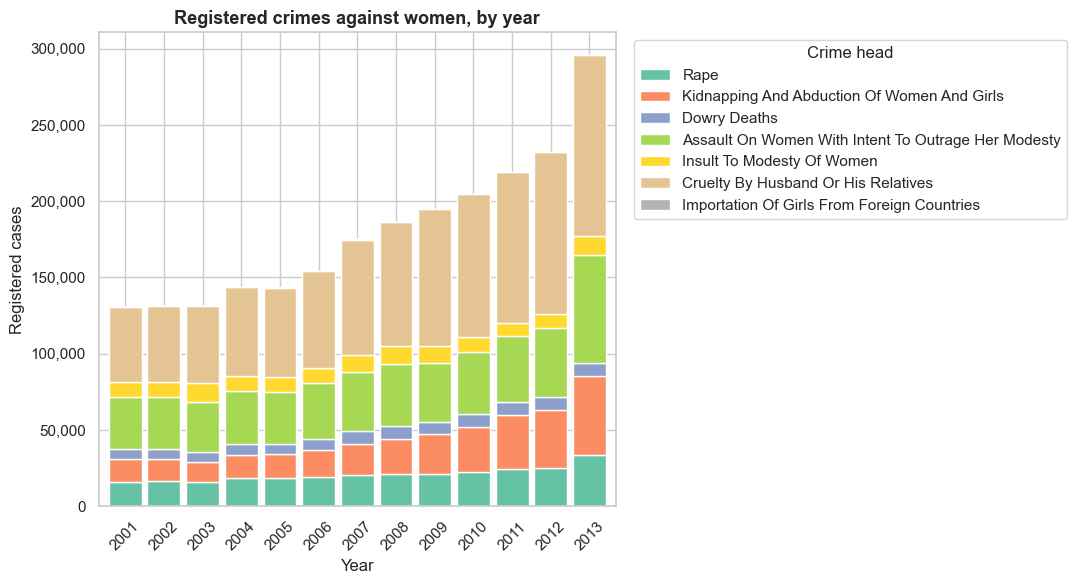

Insight: the largest category is Cruelty By Husband Or His Relatives (42% of these cases).
Insight: these crimes combined changed by +126.3% between 2001 and 2013. Part of any rise may be better reporting.


In [23]:
women_keys = ("women", "girls", "dowry", "cruelty", "modesty", "rape")
parts_of_other_heads = ("custodial_rape", "other_rape", "attempt_to_commit_rape")
women_cols = [c for c in CRIME_COLS
              if any(k in c for k in women_keys) and c not in parts_of_other_heads]

women_by_year = state_year.groupby("year")[women_cols].sum()
women_by_year = women_by_year.loc[:, women_by_year.sum() > 0]

if women_by_year.shape[1] < 2:
    print("Fewer than 2 women-related columns were found in this file, so this chart is skipped.")
    print("Columns checked:", women_cols)
else:
    fig, ax = plt.subplots(figsize=(11, 6))
    women_by_year.plot(kind="bar", stacked=True, ax=ax, colormap="Set2", width=0.85)
    ax.set_title("Registered crimes against women, by year", fontsize=13, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Registered cases")
    ax.tick_params(axis="x", rotation=45)
    ax.yaxis.set_major_formatter(thousands)
    ax.legend([pretty(c) for c in women_by_year.columns], bbox_to_anchor=(1.02, 1), loc="upper left", title="Crime head")
    plt.tight_layout()
    save_png(fig, "03_06_crimes_against_women.png")
    plt.show()

    totals = women_by_year.sum().sort_values(ascending=False)
    combined = women_by_year.sum(axis=1)
    change = (combined.loc[last_year] / combined.loc[first_year] - 1) * 100
    print(f"Insight: the largest category is {pretty(totals.index[0])} ({totals.iloc[0] / totals.sum() * 100:.0f}% of these cases).")
    print(f"Insight: these crimes combined changed by {change:+.1f}% between {first_year} and {last_year}. "
          "Part of any rise may be better reporting.")

## Chart 7: How much do districts differ inside a state?
**Question:** does a state's total come from many similar districts or from a few very large ones? Each box covers the district-years of one state. The scale is logarithmic because a few districts are huge.

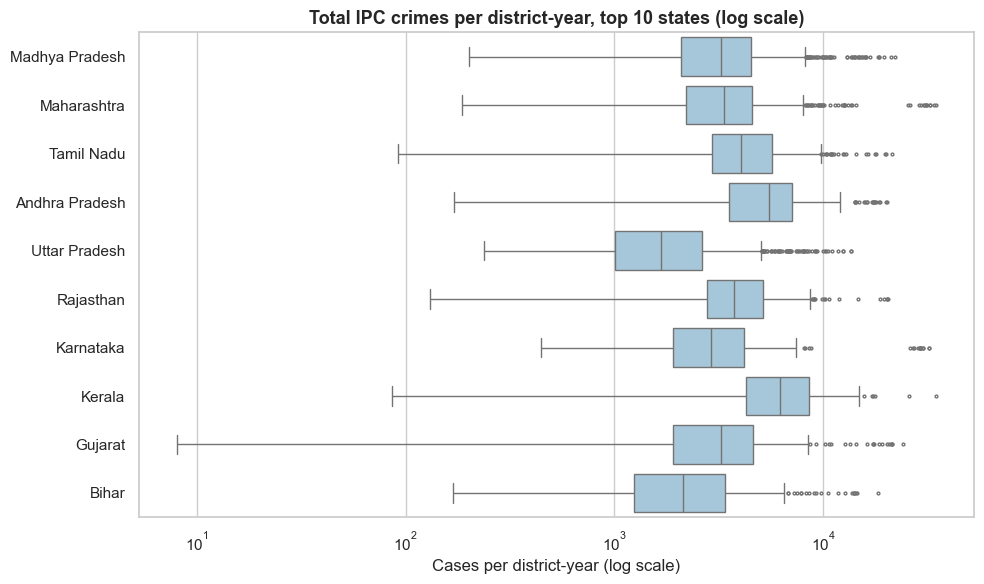

Insight: the typical district is largest in Kerala (median 6,231 cases per year).
Insight: Karnataka has the biggest gap between its largest district and its typical district (11.2 times).


In [24]:
box_df = df[df["state"].isin(top10) & (df[TOTAL_COL] > 0)]

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=box_df, x=TOTAL_COL, y="state", order=top10, color="#9ecae1", fliersize=2, ax=ax)
ax.set_xscale("log")
ax.set_title("Total IPC crimes per district-year, top 10 states (log scale)", fontsize=13, fontweight="bold")
ax.set_xlabel("Cases per district-year (log scale)")
ax.set_ylabel("")
plt.tight_layout()
save_png(fig, "03_07_district_spread_boxplot.png")
plt.show()

medians = box_df.groupby("state")[TOTAL_COL].median().sort_values(ascending=False)
ratio = (box_df.groupby("state")[TOTAL_COL].max() / box_df.groupby("state")[TOTAL_COL].median()).sort_values(ascending=False)
print(f"Insight: the typical district is largest in {medians.index[0]} (median {medians.iloc[0]:,.0f} cases per year).")
print(f"Insight: {ratio.index[0]} has the biggest gap between its largest district and its typical district ({ratio.iloc[0]:.1f} times).")

## Chart 8: From state to district (interactive treemap)
**Question:** which districts drive the total of the biggest states? Click a state to zoom in. Each state shows its 6 largest districts and the rest grouped together.

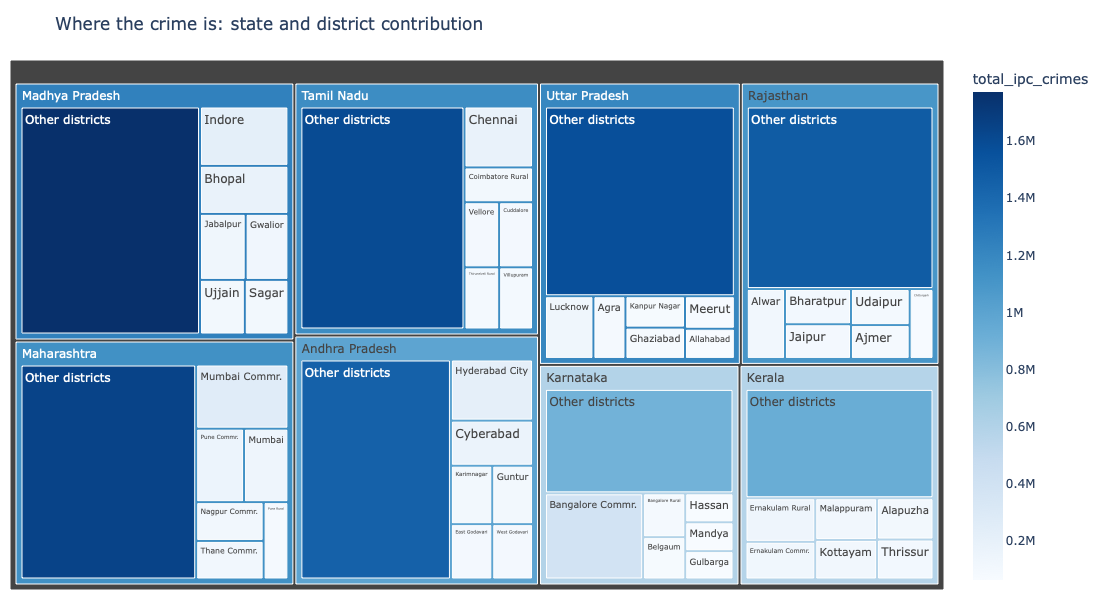

Insight: the single largest district in this view is Bangalore Commr. (Karnataka) with 380,665 cases over the period.


In [25]:
dist_totals = df.groupby(["state", "district"])[TOTAL_COL].sum().reset_index()

parts = []
for st in top10[:8]:
    d = dist_totals[dist_totals["state"] == st].sort_values(TOTAL_COL, ascending=False)
    parts.append(d.head(6))
    leftover = d[TOTAL_COL].iloc[6:].sum()
    if leftover > 0:
        parts.append(pd.DataFrame({"state": [st], "district": ["Other districts"], TOTAL_COL: [leftover]}))
tree = pd.concat(parts, ignore_index=True)

fig = px.treemap(tree, path=["state", "district"], values=TOTAL_COL,
                 color=TOTAL_COL, color_continuous_scale="Blues",
                 title="Where the crime is: state and district contribution")
fig.update_layout(height=600, margin=dict(t=60, l=10, r=10, b=10))
fig.show()
save_html(fig, "03_08_state_district_treemap.html")

named = tree[tree["district"] != "Other districts"].sort_values(TOTAL_COL, ascending=False).iloc[0]
print(f"Insight: the single largest district in this view is {named['district']} ({named['state']}) with {named[TOTAL_COL]:,.0f} cases over the period.")

## Chart 9: Trend in the top 5 states
**Question:** do the biggest states follow the same pattern as the country?

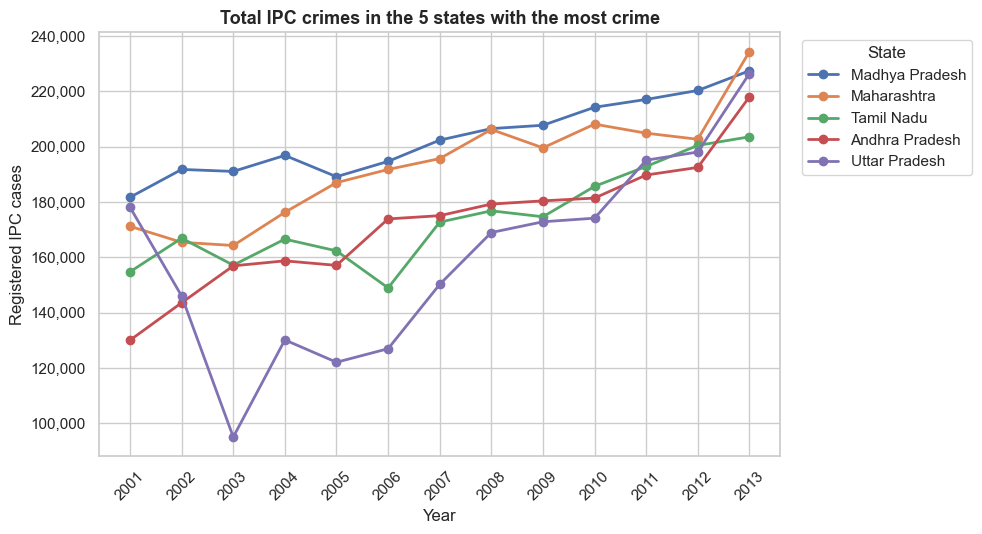

Insight: among these states, Andhra Pradesh changed the most (+67.6%) and Madhya Pradesh the least (+25.2%) between 2001 and 2013.


In [26]:
top5 = top10[:5]
trend5 = (
    state_year[state_year["state"].isin(top5)]
    .pivot_table(index="year", columns="state", values=TOTAL_COL, aggfunc="sum")[top5]
)

fig, ax = plt.subplots(figsize=(10, 5.5))
trend5.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Total IPC crimes in the 5 states with the most crime", fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Registered IPC cases")
ax.set_xticks(trend5.index)
ax.tick_params(axis="x", rotation=45)
ax.yaxis.set_major_formatter(thousands)
ax.legend(title="State", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_png(fig, "03_09_top5_state_trends.png")
plt.show()

growth5 = ((trend5.loc[last_year] / trend5.loc[first_year] - 1) * 100).sort_values(ascending=False)
print(f"Insight: among these states, {growth5.index[0]} changed the most ({growth5.iloc[0]:+.1f}%) "
      f"and {growth5.index[-1]} the least ({growth5.iloc[-1]:+.1f}%) between {first_year} and {last_year}.")

## Chart 10: Map of India (interactive)
**Question:** where is crime concentrated geographically?

State boundaries come from a free GeoJSON file on GitHub (the 35 states and UTs that existed up to 2013, which matches this dataset). It is downloaded once, simplified to a small size and saved in `data/raw/`. The map is for illustration only and is not an official boundary.

*If the download fails* (for example no internet or a certificate error on your Mac), download the file in your browser from the link in the next cell, save it as `data/raw/india_states_original.geojson` and run the cell again.

In [27]:
GEOJSON_URL = "https://raw.githubusercontent.com/Subhash9325/GeoJSON-Data-of-Indian-States/master/Indian_States"
ORIGINAL_FILE = RAW_DIR / "india_states_original.geojson"
GEO_FILE = RAW_DIR / "india_states_simplified.geojson"
NAME_KEY = "NAME_1"          # the property that holds the state name in this file


def simplify_ring(ring, decimals=2):
    # Round coordinates to ~1 km and drop repeated points. Keeps the map small and fast.
    out = []
    for x, y in ring:
        point = [round(x, decimals), round(y, decimals)]
        if not out or point != out[-1]:
            out.append(point)
    if len(out) >= 3 and out[0] != out[-1]:
        out.append(out[0])
    return out if len(out) >= 4 else None


def simplify_geometry(geometry):
    polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
    result = []
    for polygon in polygons:
        outer = simplify_ring(polygon[0])
        if outer is None:
            continue
        holes = [h for h in (simplify_ring(r) for r in polygon[1:]) if h]
        result.append([outer] + holes)
    return {"type": "MultiPolygon", "coordinates": result}


def load_india_geojson():
    if not GEO_FILE.exists():
        if ORIGINAL_FILE.exists():
            raw = json.loads(ORIGINAL_FILE.read_text())
        else:
            print("Downloading India state boundaries (one time, about 14 MB)...")
            with urllib.request.urlopen(GEOJSON_URL, timeout=90) as response:
                raw = json.load(response)
        features = [
            {"type": "Feature",
             "properties": {NAME_KEY: f["properties"][NAME_KEY]},
             "geometry": simplify_geometry(f["geometry"])}
            for f in raw["features"]
        ]
        GEO_FILE.write_text(json.dumps({"type": "FeatureCollection", "features": features}, separators=(",", ":")))
        print(f"Saved simplified map: {GEO_FILE.name} ({GEO_FILE.stat().st_size / 1e6:.1f} MB)")
    return json.loads(GEO_FILE.read_text())


try:
    india_geo = load_india_geojson()
    print("Map file ready:", len(india_geo["features"]), "regions")
except Exception as err:
    india_geo = None
    print("Could not load the map file:", err)
    print("Download", GEOJSON_URL, "and save it as", ORIGINAL_FILE)

Map file ready: 35 regions


**Matching state names.** The map file and our data spell some names differently (for example *Orissa* vs *Odisha*, *and* vs *&*). The code lowercases both, removes symbols, and uses a small list of alternative spellings. Any state that still does not match is printed, so nothing disappears silently.

In [28]:
if india_geo is None:
    print("Skipping the map because the boundary file is not available.")
else:
    def make_key(name):
        return re.sub(r"[^a-z0-9]", "", name.lower().replace("&", "and"))

    ALTERNATIVES = {
        "odisha": ["orissa"],
        "uttarakhand": ["uttaranchal"],
        "aandnislands": ["andamanandnicobar", "andamanandnicobarislands"],
        "dandnhaveli": ["dadraandnagarhaveli"],
        "puducherry": ["pondicherry"],
        "chhattisgarh": ["chattisgarh"],
        "delhi": ["nctofdelhi"],
    }
    geo_names = {make_key(f["properties"][NAME_KEY]): f["properties"][NAME_KEY] for f in india_geo["features"]}

    def to_geo_name(state):
        key = make_key(state)
        for candidate in [key] + ALTERNATIVES.get(key, []):
            if candidate in geo_names:
                return geo_names[candidate]
        return None

    MAP_YEAR = None      # None = average per year over all years. Or set a year, e.g. 2012.
    if MAP_YEAR is None:
        values = state_year.groupby("state")[TOTAL_COL].mean()
        label = "Average IPC cases per year"
    else:
        values = state_year[state_year["year"] == MAP_YEAR].set_index("state")[TOTAL_COL]
        label = f"IPC cases in {MAP_YEAR}"

    map_df = values.rename("cases").reset_index()
    map_df["geo_name"] = map_df["state"].map(to_geo_name)

    unmatched = map_df.loc[map_df["geo_name"].isna(), "state"].tolist()
    no_data = sorted(set(geo_names.values()) - set(map_df["geo_name"].dropna()))
    print("States in the data that did not match the map:", unmatched or "none")
    print("Map regions with no data:", no_data or "none")

States in the data that did not match the map: none
Map regions with no data: none


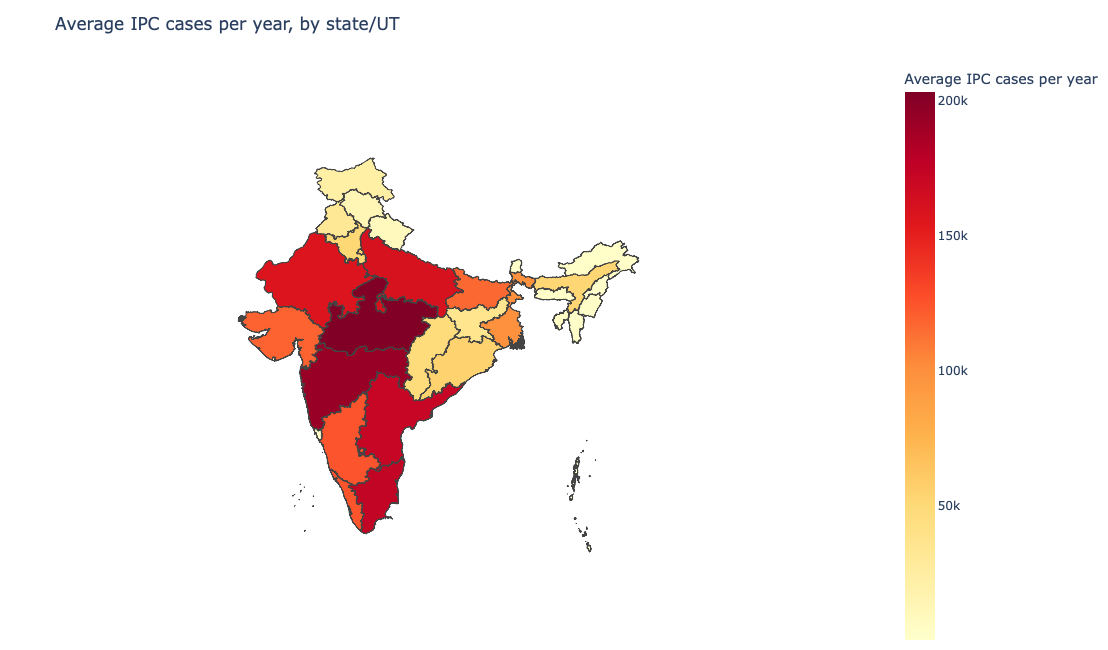

Insight: the darkest regions are Madhya Pradesh (203,171), Maharashtra (192,909), Tamil Nadu (174,135).
Note: this map shows counts, not crime per person, so populous states look darker.


In [29]:
if india_geo is not None:
    fig = px.choropleth(
        map_df.dropna(subset=["geo_name"]),
        geojson=india_geo, locations="geo_name", featureidkey=f"properties.{NAME_KEY}",
        color="cases", hover_name="state", color_continuous_scale="YlOrRd",
        labels={"cases": label},
    )
    fig.update_geos(fitbounds="locations", visible=False)
    fig.update_layout(title=f"{label}, by state/UT", height=650, margin=dict(l=0, r=0, t=60, b=0))
    fig.show()
    save_html(fig, "03_10_india_map.html")

    top3 = map_df.sort_values("cases", ascending=False).head(3)
    names = ", ".join(f"{r.state} ({r.cases:,.0f})" for r in top3.itertuples())
    print(f"Insight: the darkest regions are {names}.")
    print("Note: this map shows counts, not crime per person, so populous states look darker.")

## Saved files

In [30]:
for p in sorted(VISUALS_DIR.glob("03_*")):
    print(f"{p.name:<42} {p.stat().st_size / 1024:>8,.0f} KB")

03_01_national_trend.png                         67 KB
03_02_top10_states.png                           78 KB
03_03_state_year_heatmap.png                    192 KB
03_04_crime_composition.png                      74 KB
03_05_serious_crime_growth.html                  13 KB
03_06_crimes_against_women.png                  102 KB
03_07_district_spread_boxplot.png                71 KB
03_08_state_district_treemap.html                14 KB
03_09_top5_state_trends.png                     146 KB
03_10_india_map.html                          1,127 KB


## Summary of Part 3
Ten charts were created and saved in `visuals/`. For your README, embed the PNG charts with, for example:

```
![National trend](visuals/03_01_national_trend.png)
```

The interactive HTML charts (5, 8 and 10) can be opened in a browser and linked from the README. GitHub does not display HTML files inline, so mention them as extra files.

**Remember when writing your report:** all charts use registered **counts**, not rates per person, and changes over time can partly reflect changes in reporting.